# **Anomaly Detection on Financial Data (BTC)**


Shayan - 2026

The primary objective of this notebook is to explore **graph anomaly detection** by assigning anomaly scores to individual nodes and evaluating detection performance under class imbalance using **ROC-AUC, PR-AUC (Average Precision), and F1-score**, with the classification threshold selected on the validation set. The study examines and compares four learning paradigms: **supervised, unsupervised, self-supervised, and one-class learning**, alongside different anomaly detection approaches, including **reconstruction-based methods** (e.g., autoencoders) and **distance- and density-based techniques** (e.g., kNN distance and Local Outlier Factor). Each paradigm and method will be conceptually introduced before its practical implementation to provide a clear understanding of its underlying principles.

The main purpose of this notebook is to **demonstrate, explain, and compare different anomaly detection methodologies rather than maximize predictive performance** on a specific dataset. Accordingly, some methods may not be ideally suited to the dataset, and their performance may vary considerably. Suggestions for additional methods or potential methodological extensions are welcome.

**Graph anomaly detection** focuses on identifying unusual, irregular, or potentially suspicious patterns within graph-structured data, where **nodes** represent entities such as users, transactions, devices, or accounts, and **edges** describe relationships or interactions between them. Anomalies can occur at different structural levels, including **node anomalies**, where individual entities exhibit abnormal behavior; **edge anomalies**, characterized by unexpected or uncommon relationships; and **subgraph anomalies**, involving groups of interconnected nodes that collectively form suspicious patterns, such as coordinated fraudulent activities.

Unlike traditional tabular anomaly detection, graph-based approaches consider both **individual node attributes and the structural characteristics of their neighborhoods**, allowing the identification of entities that may appear normal in isolation but exhibit anomalous behavior within their relational context. These dependencies can also reveal collective anomalies that conventional methods might overlook. Most graph anomaly detection models assign an **anomaly score** to each node, where higher values typically indicate a greater degree of abnormality. These scores can be used to rank potentially anomalous nodes, evaluated through **ROC-AUC and PR-AUC**, or converted into binary predictions using a selected decision threshold, with classification performance assessed through metrics such as the **F1-score**.

In [1]:
import os, random
import numpy as np
import pandas as pd

SEED = 42

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

seed_everything(SEED)

def as_numpy(x):
    """Convert pandas/series/list to numpy 1D array."""
    if isinstance(x, (pd.Series, pd.DataFrame)):
        x = x.values
    x = np.asarray(x)
    return x

# **Data Loading**
Data Source: [Elliptic dataset](https://www.kaggle.com/datasets/ellipticco/elliptic-data-set)

## **Data Loading & Cleaning**

In [2]:
DATA_PATH = "/kaggle/input/datasets/organizations/ellipticco/elliptic-data-set/elliptic_bitcoin_dataset/"

features_df = pd.read_csv(DATA_PATH + "elliptic_txs_features.csv", header=None)
edges_df    = pd.read_csv(DATA_PATH + "elliptic_txs_edgelist.csv")
classes_df  = pd.read_csv(DATA_PATH + "elliptic_txs_classes.csv")

print("Features shape:", features_df.shape)
print("Edges shape:", edges_df.shape)
print("Classes shape:", classes_df.shape)

Features shape: (203769, 167)
Edges shape: (234355, 2)
Classes shape: (203769, 2)


In [3]:
# First column in features is transaction id
features_df = features_df.rename(columns={0: "txId"})

# Merge labels
data_df = features_df.merge(classes_df, on="txId", how="left")

print("Merged shape:", data_df.shape)
data_df.head()

Merged shape: (203769, 168)


,txId,1,2,3,4,5,6,7,8,9,...,158,159,160,161,162,163,164,165,166,class
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,unknown
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,unknown
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,unknown
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,2
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,unknown


In [4]:
# Keep only labeled nodes
data_df = data_df[data_df["class"] != "unknown"].copy()

# Map labels:
# illicit (1) → anomaly = 1
# licit (2) → normal = 0
label_map = {"1": 1, "2": 0}
data_df["y"] = data_df["class"].map(label_map).astype(int)

print("Class distribution:")
print(data_df["y"].value_counts(normalize=True))

Class distribution:
y
0    0.902392
1    0.097608
Name: proportion, dtype: float64


In [5]:
# Remove id + class columns
feature_cols = [c for c in data_df.columns if c not in ["txId", "class", "y"]]

X = data_df[feature_cols].values.astype(np.float32)
y = data_df["y"].values.astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (46564, 166)
y shape: (46564,)


In [6]:
# Map txId → index in X
txid_to_idx = {txid: i for i, txid in enumerate(data_df["txId"].values)}

print("Total labeled nodes:", len(txid_to_idx))

Total labeled nodes: 46564


In [7]:
# Keep edges where both endpoints are in labeled set
edges_filtered = edges_df[
    edges_df["txId1"].isin(txid_to_idx) &
    edges_df["txId2"].isin(txid_to_idx)
].copy()

# Convert to index form
edge_index = np.array([
    [txid_to_idx[a], txid_to_idx[b]]
    for a, b in zip(edges_filtered["txId1"], edges_filtered["txId2"])
]).T  # shape [2, num_edges]

print("Edge index shape:", edge_index.shape)

Edge index shape: (2, 36624)


## **Graph sanity check**

In [8]:
# Basic stats
num_nodes = X.shape[0]
num_edges = edge_index.shape[1]

print("Number of nodes:", num_nodes)
print("Number of edges:", num_edges)

# Undirected assumption (Elliptic is directed, but many GNNs treat as undirected)
avg_degree = num_edges * 2 / num_nodes
print("Average degree (approx):", round(avg_degree, 2))

Number of nodes: 46564
Number of edges: 36624
Average degree (approx): 1.57


In [9]:
num_anomaly = y.sum()
num_normal = len(y) - num_anomaly

print("Normal nodes:", num_normal)
print("Anomalous nodes:", num_anomaly)
print("Anomaly ratio:", round(num_anomaly / len(y), 4))

Normal nodes: 42019
Anomalous nodes: 4545
Anomaly ratio: 0.0976


In [10]:
# Compute degree
degrees = np.zeros(num_nodes, dtype=int)
for src, dst in edge_index.T:
    degrees[src] += 1
    degrees[dst] += 1

print("Degree stats:")
print("Min:", degrees.min())
print("Mean:", round(degrees.mean(), 2))
print("Max:", degrees.max())


Degree stats:
Min: 0
Mean: 1.57
Max: 453


## **Train/Test Split**

In [11]:
# Extract time step (column 1 in original features)
# After merge, feature columns start from column index 1 in original CSV
time_col_index = 1  # known from dataset structure
time_steps = data_df.iloc[:, time_col_index].values

unique_times = np.sort(np.unique(time_steps))
print("Total timesteps:", len(unique_times))

# Split 60% train, 20% val, 20% test by time
n = len(unique_times)
train_times = unique_times[:int(0.6 * n)]
val_times   = unique_times[int(0.6 * n):int(0.8 * n)]
test_times  = unique_times[int(0.8 * n):]

train_idx = np.where(np.isin(time_steps, train_times))[0]
val_idx   = np.where(np.isin(time_steps, val_times))[0]
test_idx  = np.where(np.isin(time_steps, test_times))[0]

print("Train size:", len(train_idx))
print("Val size:", len(val_idx))
print("Test size:", len(test_idx))

Total timesteps: 49
Train size: 26381
Val size: 8999
Test size: 11184


In [12]:
# Make sure no overlap
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

print("Split sanity check passed.")

Split sanity check passed.


# **2 - Preparing the Evaluation metrics**

Anomaly detection is primarily a scoring task, followed by a classification decision in which each node receives an anomaly score indicating its degree of abnormality. Model performance can first be assessed through threshold-independent ranking metrics, including ROC-AUC and PR-AUC (Average Precision). ROC-AUC measures how effectively a model ranks anomalous observations above normal ones, with values of 0.5 indicating random discrimination and 1.0 representing perfect discrimination. However, ROC-AUC may appear favorable even when precision is poor under severe class imbalance. In contrast, PR-AUC emphasizes the positive class by examining the trade-off between precision and recall, making it particularly informative for rare-event detection. Its random-ranking baseline approximately corresponds to the anomaly prevalence; for example, a dataset containing 2% anomalies has a baseline Average Precision of approximately 0.02.

Beyond ranking performance, anomaly detection requires threshold-based evaluation to determine which nodes should be classified as anomalous. A decision threshold is selected using validation data, typically by identifying the score cutoff that maximizes the F1-score, and is subsequently applied to the test set without further adjustment. Precision measures the proportion of predicted anomalies that are genuinely anomalous, while recall represents the proportion of actual anomalies successfully detected. The F1-score combines these measures through their harmonic mean, balancing false alarms against missed anomalies. Accordingly, ROC-AUC and PR-AUC assess ranking quality, whereas precision, recall, and F1-score evaluate classification decisions. Selecting the threshold exclusively on validation data prevents test-set leakage and supports a more reliable assessment of model generalization.

In [13]:
def print_split_distribution(name, idx):
    y_split = y[idx]
    anomaly_ratio = y_split.mean()
    print(f"{name}:")
    print("  Size:", len(idx))
    print("  Anomalies:", int(y_split.sum()))
    print("  Ratio:", round(float(anomaly_ratio), 4))
    print()

print_split_distribution("Train", train_idx)
print_split_distribution("Validation", val_idx)
print_split_distribution("Test", test_idx)

Train:
  Size: 26381
  Anomalies: 2871
  Ratio: 0.1088

Validation:
  Size: 8999
  Anomalies: 1038
  Ratio: 0.1153

Test:
  Size: 11184
  Anomalies: 636
  Ratio: 0.0569



In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

def plot_curves(scores, y_true, idx, title=""):
    y_eval = y_true[idx]
    s_eval = scores[idx]

    # PR curve
    precision, recall, _ = precision_recall_curve(y_eval, s_eval)
    roc_fpr, roc_tpr, _ = roc_curve(y_eval, s_eval)

    plt.figure(figsize=(12,4))

    plt.subplot(1,2,1)
    plt.plot(recall, precision)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("PR Curve")

    plt.subplot(1,2,2)
    plt.plot(roc_fpr, roc_tpr)
    plt.xlabel("FPR")
    plt.ylabel("TPR")
    plt.title("ROC Curve")

    plt.suptitle(title)
    plt.show()

In [15]:
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_fscore_support

def evaluate_scores(scores, y_true, val_idx, test_idx):
    """
    scores: array-like shape [N], higher = more anomalous
    y_true: array-like shape [N], binary {0,1} where 1 = anomaly
    val_idx/test_idx: arrays of indices
    Threshold picked on val by max F1, then reported on test.
    """
    scores = as_numpy(scores).reshape(-1)
    y_true = as_numpy(y_true).reshape(-1).astype(int)
    val_idx = as_numpy(val_idx).astype(int)
    test_idx = as_numpy(test_idx).astype(int)

    # Ranking metrics on test
    y_test = y_true[test_idx]
    s_test = scores[test_idx]

    # Guard against degenerate cases
    if len(np.unique(y_test)) < 2:
        raise ValueError("Test split has only one class; cannot compute AUC metrics.")

    roc = roc_auc_score(y_test, s_test)
    pr  = average_precision_score(y_test, s_test)

    # Threshold selection: maximize F1 on validation
    y_val = y_true[val_idx]
    s_val = scores[val_idx]
    # Candidate thresholds = unique scores (fast enough for Kaggle scale; can downsample later if huge)
    thresholds = np.unique(s_val)
    best = {"f1": -1, "thr": None, "precision": None, "recall": None}

    for thr in thresholds:
        pred = (s_val >= thr).astype(int)
        p, r, f1, _ = precision_recall_fscore_support(y_val, pred, average="binary", zero_division=0)
        if f1 > best["f1"]:
            best.update({"f1": f1, "thr": float(thr), "precision": float(p), "recall": float(r)})

    # Apply chosen threshold on test
    pred_test = (s_test >= best["thr"]).astype(int)
    p_t, r_t, f1_t, _ = precision_recall_fscore_support(y_test, pred_test, average="binary", zero_division=0)

    return {
        "ROC_AUC_test": float(roc),
        "PR_AUC_test": float(pr),
        "thr_from_val_maxF1": float(best["thr"]),
        "Precision_test": float(p_t),
        "Recall_test": float(r_t),
        "F1_test": float(f1_t),
        "Val_bestF1": float(best["f1"]),
        "Val_precision_at_bestF1": float(best["precision"]),
        "Val_recall_at_bestF1": float(best["recall"]),
    }

Random baseline:
{'ROC_AUC_test': 0.48996292480257964, 'PR_AUC_test': 0.0551269819843387, 'thr_from_val_maxF1': -2.9543905990807193, 'Precision_test': 0.05686397420972508, 'Recall_test': 0.9984276729559748, 'F1_test': 0.10759976277217656, 'Val_bestF1': 0.20700668729414112, 'Val_precision_at_bestF1': 0.11546598374345841, 'Val_recall_at_bestF1': 0.9990366088631984}


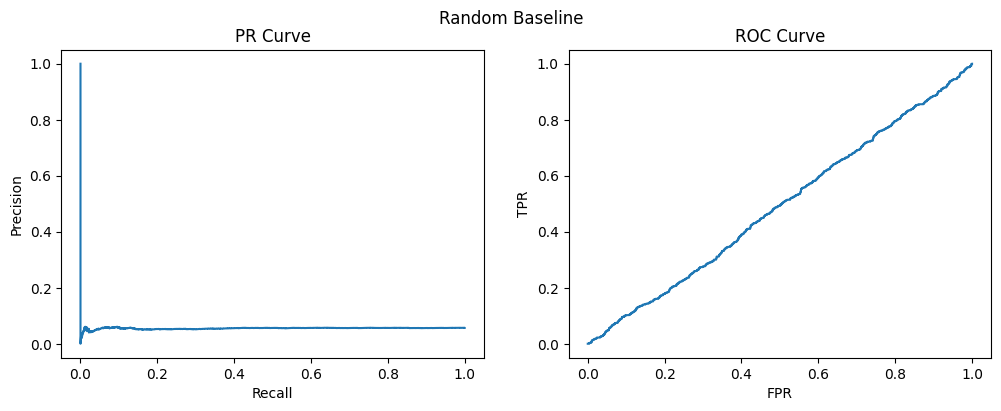

In [16]:
random_scores = np.random.randn(len(y))

print("Random baseline:")
print(evaluate_scores(random_scores, y, val_idx, test_idx))

plot_curves(random_scores, y, test_idx, title="Random Baseline")

# **3 - Unsupervised**

We begin by exploring **classical unsupervised anomaly detection techniques** applied directly to node features. These methods operate without labeled training data and assign an **anomaly score to each node** based on its deviation from typical patterns in the feature space. Their detection mechanisms rely entirely on **distance- or density-based characteristics**, without explicitly incorporating graph connectivity or neighborhood structure.

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled feature shape:", X_scaled.shape)

Scaled feature shape: (46564, 166)


## **kNN Distance (Distance-Based)**

The k-Nearest Neighbors (kNN) distance-based anomaly detection method identifies unusual observations based on their geometric separation from surrounding data points. For each node, the algorithm determines its k nearest neighbors in the feature space and calculates their average distance, using this value as an anomaly score. Nodes with larger average distances are considered more likely to be anomalous, as they exhibit greater isolation from nearby observations. This approach assumes that normal nodes tend to occupy densely populated regions, whereas anomalies are more likely to appear in sparse areas. Unlike learning-based detection methods, kNN distance-based detection does not train a predictive model; instead, it directly quantifies geometric isolation through neighborhood distances.

kNN Results: {'ROC_AUC_test': 0.289161646191236, 'PR_AUC_test': 0.037359579854275154, 'thr_from_val_maxF1': 0.008741359976637695, 'Precision_test': 0.05686695278969957, 'Recall_test': 1.0, 'F1_test': 0.10761421319796954, 'Val_bestF1': 0.20683471156720135, 'Val_precision_at_bestF1': 0.11534614957217469, 'Val_recall_at_bestF1': 1.0}


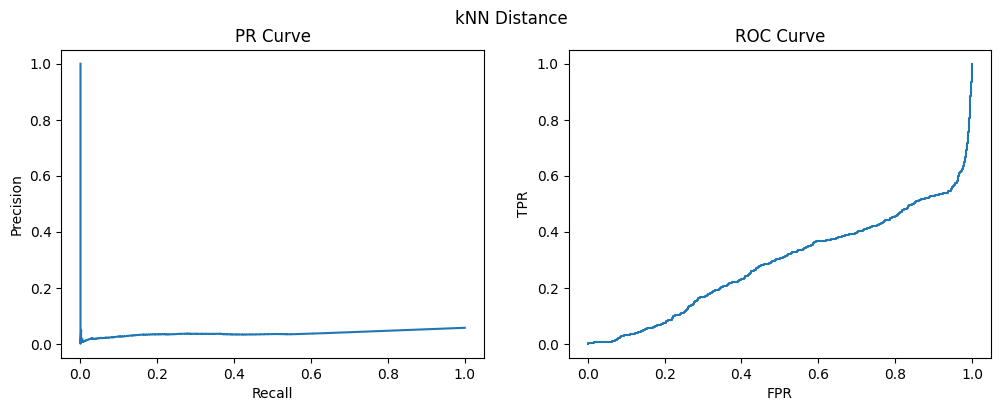

In [18]:
from sklearn.neighbors import NearestNeighbors

def knn_distance_scores(X, k=20):
    nn = NearestNeighbors(n_neighbors=k)
    nn.fit(X)
    distances, _ = nn.kneighbors(X)
    
    # first column is distance to itself (0), remove it
    scores = distances[:, 1:].mean(axis=1)
    return scores

knn_scores = knn_distance_scores(X_scaled, k=10)

results_knn = evaluate_scores(knn_scores, y, val_idx, test_idx)
print("kNN Results:", results_knn)

plot_curves(knn_scores, y, test_idx, title="kNN Distance")

## **LOF (Density-Based)**

The Local Outlier Factor (LOF) algorithm identifies anomalies by examining differences in local data density between individual observations and their surrounding neighbors. For each node, LOF estimates its local density and compares it with the densities of nearby nodes, assigning higher anomaly scores to observations located in substantially less dense regions than their neighbors. Unlike conventional distance-based approaches, LOF accounts for variations in local density, making it particularly effective for detecting outliers in datasets containing clusters with different density distributions.

LOF Results: {'ROC_AUC_test': 0.6687279236219927, 'PR_AUC_test': 0.1797236832962593, 'thr_from_val_maxF1': 1.5789730548858643, 'Precision_test': 0.07607555089192025, 'Recall_test': 0.6839622641509434, 'F1_test': 0.1369216241737488, 'Val_bestF1': 0.26331508213041316, 'Val_precision_at_bestF1': 0.17751677852348993, 'Val_recall_at_bestF1': 0.5096339113680154}


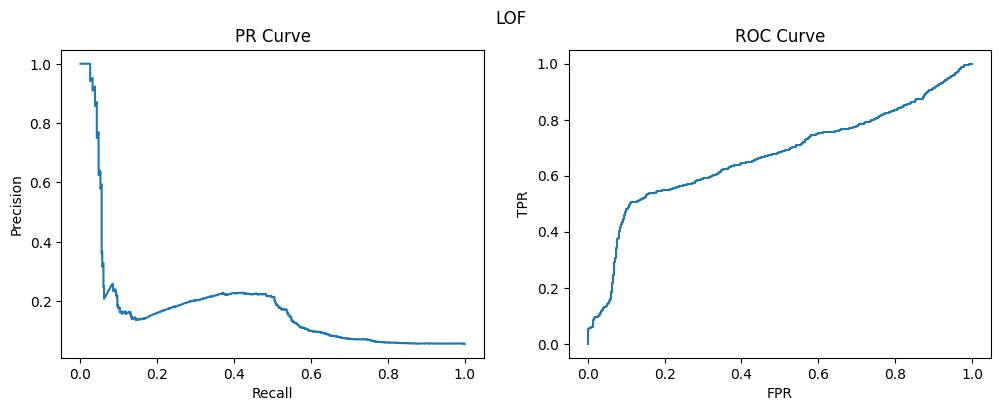

In [19]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(n_neighbors=20, novelty=True)
lof.fit(X_scaled[train_idx])

# LOF gives negative scores for anomalies → invert
lof_scores = -lof.score_samples(X_scaled)

results_lof = evaluate_scores(lof_scores, y, val_idx, test_idx)
print("LOF Results:", results_lof)

plot_curves(lof_scores, y, test_idx, title="LOF")

## **Comparing results**

In [20]:
baseline_results = pd.DataFrame([
    {"Method": "kNN", **results_knn},
    {"Method": "LOF", **results_lof},
])

baseline_results

,Method,ROC_AUC_test,PR_AUC_test,thr_from_val_maxF1,Precision_test,Recall_test,F1_test,Val_bestF1,Val_precision_at_bestF1,Val_recall_at_bestF1
0,kNN,0.289162,0.037360,0.008741,0.056867,1.000000,0.107614,0.206835,0.115346,1.000000
1,LOF,0.668728,0.179724,1.578973,0.076076,0.683962,0.136922,0.263315,0.177517,0.509634


# **4 - Autoencoder (Reconstruction-Based Detection)**

An **Autoencoder (AE)** is a neural network designed to reconstruct its input by learning a compressed representation of the original data. It consists of two main components: an **encoder**, which transforms an input vector into a lower-dimensional latent representation (bottleneck), and a **decoder**, which attempts to recover the original input from this compressed representation. By minimizing **reconstruction loss**, typically Mean Squared Error (MSE), the model learns dominant patterns, feature correlations, and underlying structures within the training data. The dimensionality reduction introduced by the bottleneck encourages the network to capture essential information rather than simply reproduce individual observations.

In **autoencoder-based anomaly detection**, the central assumption is that normal observations dominate the training data, allowing the model to learn their characteristic patterns and reconstruct them accurately. Anomalous nodes, whose features or relationships deviate from these learned patterns, are expected to produce larger **reconstruction errors**, which serve as their anomaly scores. Consequently, higher reconstruction errors indicate potentially greater abnormality. The effectiveness of this approach depends on several assumptions: **anomalies are relatively rare, the model primarily learns normal data distributions, and the bottleneck or other architectural constraints sufficiently limit memorization**. If the autoencoder reconstructs anomalous observations equally well, its ability to distinguish anomalies from normal data may be reduced.

In [21]:
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

X_t = torch.tensor(X_scaled, dtype=torch.float32).to(device)  # use scaled features

Device: cpu


In [22]:
class AE(nn.Module):
    def __init__(self, in_dim, hidden_dim=64, bottleneck_dim=8):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, bottleneck_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, in_dim),
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat

In [23]:
def train_ae(X_tensor, train_idx, epochs=20, lr=1e-3, batch_size=1024):
    in_dim = X_tensor.shape[1]
    model = AE(in_dim).to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss(reduction="mean")

    train_data = X_tensor[train_idx]
    n = train_data.shape[0]

    model.train()
    for ep in range(1, epochs + 1):
        perm = torch.randperm(n, device=device)
        total_loss = 0.0

        for i in range(0, n, batch_size):
            idx = perm[i:i+batch_size]
            batch = train_data[idx]

            opt.zero_grad()
            recon = model(batch)
            loss = loss_fn(recon, batch)
            loss.backward()
            opt.step()

            total_loss += loss.item() * batch.size(0)

        avg_loss = total_loss / n
        if ep == 1 or ep % 5 == 0:
            print(f"Epoch {ep:02d} | train MSE: {avg_loss:.6f}")

    return model

ae_model = train_ae(X_t, train_idx, epochs=20, lr=1e-3, batch_size=2048)

Epoch 01 | train MSE: 0.968765
Epoch 05 | train MSE: 0.658768
Epoch 10 | train MSE: 0.493289
Epoch 15 | train MSE: 0.429364
Epoch 20 | train MSE: 0.394877


AE (reconstruction) Results: {'ROC_AUC_test': 0.27042936990052063, 'PR_AUC_test': 0.036985977955955485, 'thr_from_val_maxF1': 0.046320006251335144, 'Precision_test': 0.05686695278969957, 'Recall_test': 1.0, 'F1_test': 0.10761421319796954, 'Val_bestF1': 0.20691717332801754, 'Val_precision_at_bestF1': 0.11539744302390217, 'Val_recall_at_bestF1': 1.0}


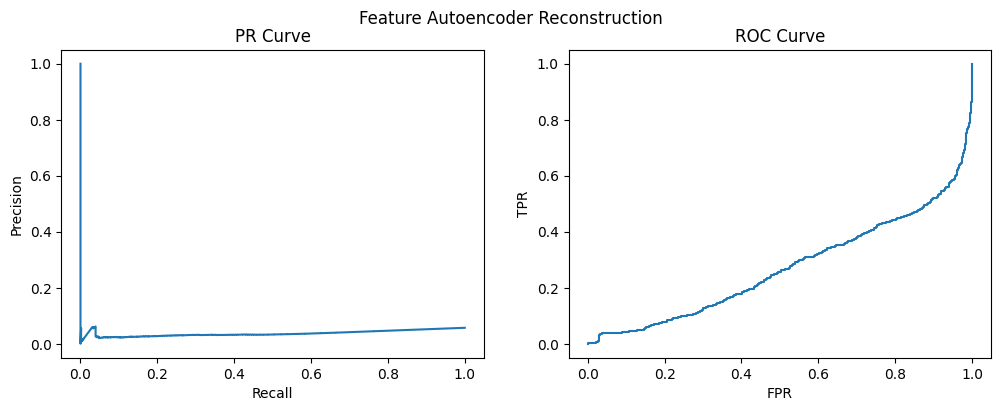

In [24]:
@torch.no_grad()
def ae_recon_scores(model, X_tensor, batch_size=4096):
    model.eval()
    n = X_tensor.shape[0]
    scores = np.zeros(n, dtype=np.float32)

    for i in range(0, n, batch_size):
        batch = X_tensor[i:i+batch_size]
        recon = model(batch)
        err = torch.mean((recon - batch) ** 2, dim=1)
        scores[i:i+batch_size] = err.detach().cpu().numpy()

    return scores

ae_scores = ae_recon_scores(ae_model, X_t)

results_ae = evaluate_scores(ae_scores, y, val_idx, test_idx)
print("AE (reconstruction) Results:", results_ae)

plot_curves(ae_scores, y, test_idx, title="Feature Autoencoder Reconstruction")

In [25]:
baseline_results = pd.concat([
    baseline_results,
    pd.DataFrame([{"Method": "AE", **results_ae}])
], ignore_index=True)

baseline_results

,Method,ROC_AUC_test,PR_AUC_test,thr_from_val_maxF1,Precision_test,Recall_test,F1_test,Val_bestF1,Val_precision_at_bestF1,Val_recall_at_bestF1
0,kNN,0.289162,0.037360,0.008741,0.056867,1.000000,0.107614,0.206835,0.115346,1.000000
1,LOF,0.668728,0.179724,1.578973,0.076076,0.683962,0.136922,0.263315,0.177517,0.509634
2,AE,0.270429,0.036986,0.046320,0.056867,1.000000,0.107614,0.206917,0.115397,1.000000


## **Normal-Only Autoencoder (one class learning)**

In **fraud and anomaly detection**, labeled anomalous samples are often scarce or unavailable, making **one-class learning** a practical approach for identifying unusual patterns. Instead of learning to distinguish between normal and anomalous classes directly, the model is trained exclusively on **normal nodes (label = 0)** to capture their underlying characteristics and typical feature distributions. During evaluation, the trained model is applied to a test set containing both normal and anomalous observations, assigning each node an **anomaly score based on its reconstruction error**. Nodes with higher reconstruction errors are considered more likely to be anomalous, as their features deviate from the patterns learned during training. By focusing exclusively on normal observations, this approach can improve anomaly separation, although its effectiveness depends on the model's ability to accurately represent normal behavior while remaining sensitive to abnormal patterns.

In [26]:
# Normal-only training indices
normal_train_idx = train_idx[y[train_idx] == 0]

print("Total train nodes:", len(train_idx))
print("Normal-only train nodes:", len(normal_train_idx))

Total train nodes: 26381
Normal-only train nodes: 23510


In [27]:
ae_oneclass = train_ae(
    X_t,
    normal_train_idx,
    epochs=20,
    lr=1e-3,
    batch_size=2048
)

Epoch 01 | train MSE: 1.060617
Epoch 05 | train MSE: 0.702599
Epoch 10 | train MSE: 0.549740
Epoch 15 | train MSE: 0.465385
Epoch 20 | train MSE: 0.415829


One-Class AE Results: {'ROC_AUC_test': 0.28304018407614906, 'PR_AUC_test': 0.03754818238160624, 'thr_from_val_maxF1': 0.06594148278236389, 'Precision_test': 0.05686695278969957, 'Recall_test': 1.0, 'F1_test': 0.10761421319796954, 'Val_bestF1': 0.2069377990430622, 'Val_precision_at_bestF1': 0.11541027351567712, 'Val_recall_at_bestF1': 1.0}


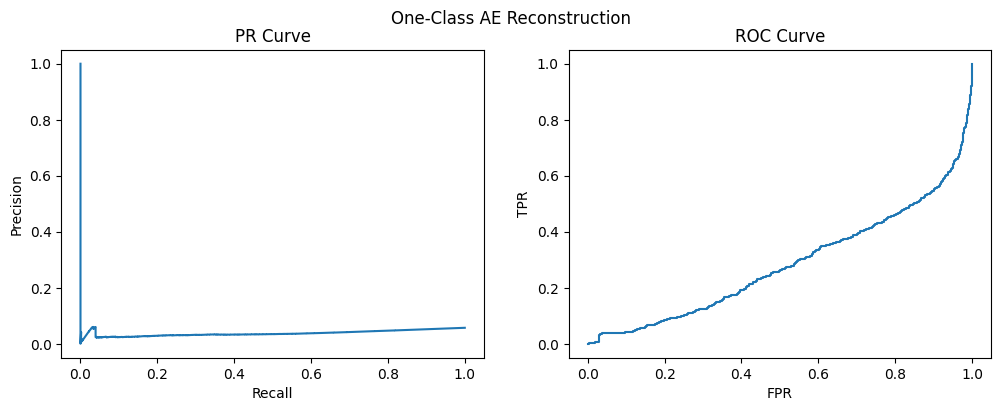

In [28]:
ae_oneclass_scores = ae_recon_scores(ae_oneclass, X_t)

results_oneclass = evaluate_scores(
    ae_oneclass_scores,
    y,
    val_idx,
    test_idx
)

print("One-Class AE Results:", results_oneclass)

plot_curves(
    ae_oneclass_scores,
    y,
    test_idx,
    title="One-Class AE Reconstruction"
)

In [29]:
baseline_results = pd.concat([
    baseline_results,
    pd.DataFrame([{"Method": "AE_oneclass", **results_oneclass}])
], ignore_index=True)

baseline_results

,Method,ROC_AUC_test,PR_AUC_test,thr_from_val_maxF1,Precision_test,Recall_test,F1_test,Val_bestF1,Val_precision_at_bestF1,Val_recall_at_bestF1
0,kNN,0.289162,0.037360,0.008741,0.056867,1.000000,0.107614,0.206835,0.115346,1.000000
1,LOF,0.668728,0.179724,1.578973,0.076076,0.683962,0.136922,0.263315,0.177517,0.509634
2,AE,0.270429,0.036986,0.046320,0.056867,1.000000,0.107614,0.206917,0.115397,1.000000
3,AE_oneclass,0.283040,0.037548,0.065941,0.056867,1.000000,0.107614,0.206938,0.115410,1.000000


## **Supervised Learning**

In **supervised anomaly detection**, a classification model is trained using **node features and their corresponding ground-truth labels** to estimate the probability that each node is anomalous. By learning from both normal and anomalous observations, the model identifies discriminative patterns and establishes a **decision boundary** that separates the two classes. During training, the model minimizes a classification loss function, typically **Binary Cross-Entropy (BCE)**, which penalizes incorrect predictions and guides parameter optimization. Through this process, the model learns to assign higher anomaly probabilities to anomalous nodes while maintaining lower probabilities for normal observations, enabling effective identification of suspicious patterns in labeled datasets.


Supervised Logistic Regression Results: {'ROC_AUC_test': 0.8262949785705598, 'PR_AUC_test': 0.16548594580159776, 'thr_from_val_maxF1': 0.9714981278294149, 'Precision_test': 0.15967571378216425, 'Recall_test': 0.7122641509433962, 'F1_test': 0.2608695652173913, 'Val_bestF1': 0.5481535119478639, 'Val_precision_at_bestF1': 0.4390951276102088, 'Val_recall_at_bestF1': 0.7292870905587668}


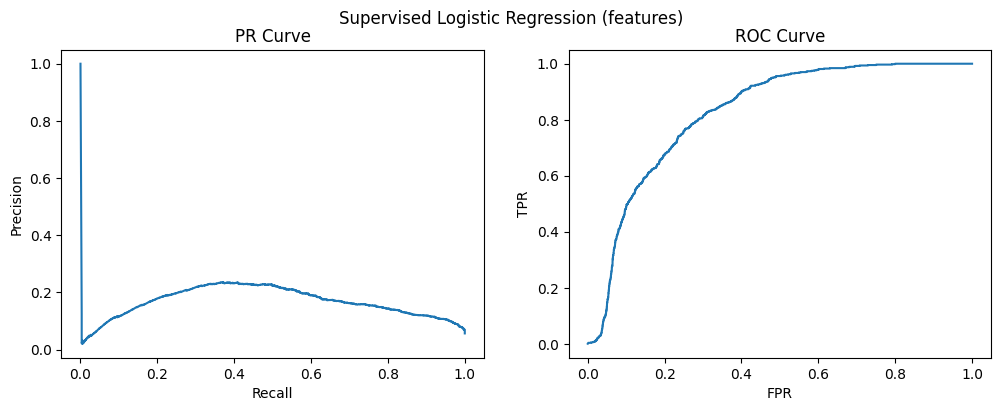

In [30]:
from sklearn.linear_model import LogisticRegression

# Train only on labeled train nodes (we already filtered unknowns)
clf = LogisticRegression(max_iter=2000, class_weight="balanced", n_jobs=-1)
clf.fit(X_scaled[train_idx], y[train_idx])

# Score = probability of anomaly (class 1)
sup_scores = clf.predict_proba(X_scaled)[:, 1]

results_sup = evaluate_scores(sup_scores, y, val_idx, test_idx)
print("Supervised Logistic Regression Results:", results_sup)

plot_curves(sup_scores, y, test_idx, title="Supervised Logistic Regression (features)")

In [31]:
baseline_results = pd.concat([
    baseline_results,
    pd.DataFrame([{"Method": "Supervised_LogReg", **results_sup}])
], ignore_index=True)

baseline_results

,Method,ROC_AUC_test,PR_AUC_test,thr_from_val_maxF1,Precision_test,Recall_test,F1_test,Val_bestF1,Val_precision_at_bestF1,Val_recall_at_bestF1
0,kNN,0.289162,0.037360,0.008741,0.056867,1.000000,0.107614,0.206835,0.115346,1.000000
1,LOF,0.668728,0.179724,1.578973,0.076076,0.683962,0.136922,0.263315,0.177517,0.509634
2,AE,0.270429,0.036986,0.046320,0.056867,1.000000,0.107614,0.206917,0.115397,1.000000
3,AE_oneclass,0.283040,0.037548,0.065941,0.056867,1.000000,0.107614,0.206938,0.115410,1.000000
4,Supervised_LogReg,0.826295,0.165486,0.971498,0.159676,0.712264,0.260870,0.548154,0.439095,0.729287



## **Self-Supervised Learning**

**Self-supervised learning** enables models to learn meaningful graph representations without relying on anomaly labels. Instead, the model is trained through an auxiliary **pretext task**, such as **link prediction**, to capture structural relationships between nodes. In this approach, node embeddings are optimized so that connected nodes exhibit higher similarity, while randomly sampled node pairs are encouraged to have lower similarity. The similarity between two nodes is calculated using the dot product of their learned embeddings, expressed as:

$$
\text{Score}(u, v) = z_u^\top z_v
$$

Through this process, the model learns **structural regularities, neighborhood relationships, and community patterns** within the graph rather than identifying anomalies directly. Once training is completed, the learned node embeddings can be treated as feature vectors and analyzed using conventional outlier detection techniques, such as **k-Nearest Neighbors (kNN)** or **Local Outlier Factor (LOF)**. Nodes exhibiting unusual embedding patterns or substantial deviations from their surrounding observations receive higher anomaly scores, allowing structural representations to support anomaly detection. The resulting anomaly score is defined as:

$$
\text{Score} = \text{Outlier score in embedding space}
$$

In [32]:
# edge_index: shape [2, num_edges]
src = torch.tensor(edge_index[0], dtype=torch.long)
dst = torch.tensor(edge_index[1], dtype=torch.long)

num_nodes = X_scaled.shape[0]
num_edges = edge_index.shape[1]

print("Nodes:", num_nodes, "Edges:", num_edges)

Nodes: 46564 Edges: 36624


In [33]:
class LinkPredEmbedding(nn.Module):
    def __init__(self, num_nodes, emb_dim=64):
        super().__init__()
        self.emb = nn.Embedding(num_nodes, emb_dim)
        nn.init.normal_(self.emb.weight, std=0.1)

    def score(self, u, v):
        # dot product
        return (self.emb(u) * self.emb(v)).sum(dim=1)

def train_linkpred_embeddings(src, dst, num_nodes, emb_dim=64, epochs=5, batch_size=200000, lr=1e-2):
    model = LinkPredEmbedding(num_nodes, emb_dim=emb_dim).to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()

    src = src.to(device)
    dst = dst.to(device)

    m = src.shape[0]
    model.train()

    for ep in range(1, epochs + 1):
        perm = torch.randperm(m, device=device)
        total_loss = 0.0

        for i in range(0, m, batch_size):
            idx = perm[i:i+batch_size]
            u_pos = src[idx]
            v_pos = dst[idx]

            # negatives: random endpoints
            u_neg = u_pos
            v_neg = torch.randint(0, num_nodes, (u_pos.shape[0],), device=device)

            # scores
            pos_logits = model.score(u_pos, v_pos)
            neg_logits = model.score(u_neg, v_neg)

            # labels
            logits = torch.cat([pos_logits, neg_logits], dim=0)
            labels = torch.cat([
                torch.ones_like(pos_logits),
                torch.zeros_like(neg_logits)
            ], dim=0)

            opt.zero_grad()
            loss = loss_fn(logits, labels)
            loss.backward()
            opt.step()

            total_loss += loss.item() * logits.shape[0]

        avg_loss = total_loss / (2 * m)
        print(f"Epoch {ep:02d} | loss: {avg_loss:.6f}")

    return model

lp_model = train_linkpred_embeddings(src, dst, num_nodes, emb_dim=64, epochs=5, batch_size=200000, lr=1e-2)

Epoch 01 | loss: 0.693980
Epoch 02 | loss: 0.682044
Epoch 03 | loss: 0.670265
Epoch 04 | loss: 0.658665
Epoch 05 | loss: 0.647156


In [34]:
with torch.no_grad():
    Z = lp_model.emb.weight.detach().cpu().numpy().astype(np.float32)

print("Embeddings shape:", Z.shape)

Embeddings shape: (46564, 64)


In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
Z_scaled = scaler.fit_transform(Z)

Self-sup Embeddings + LOF Results: {'ROC_AUC_test': 0.44888483732944096, 'PR_AUC_test': 0.050301695684393466, 'thr_from_val_maxF1': 0.974007248878479, 'Precision_test': 0.05679277345496825, 'Recall_test': 0.9984276729559748, 'F1_test': 0.10747228569010747, 'Val_bestF1': 0.20685532084495814, 'Val_precision_at_bestF1': 0.11535896865970216, 'Val_recall_at_bestF1': 1.0}


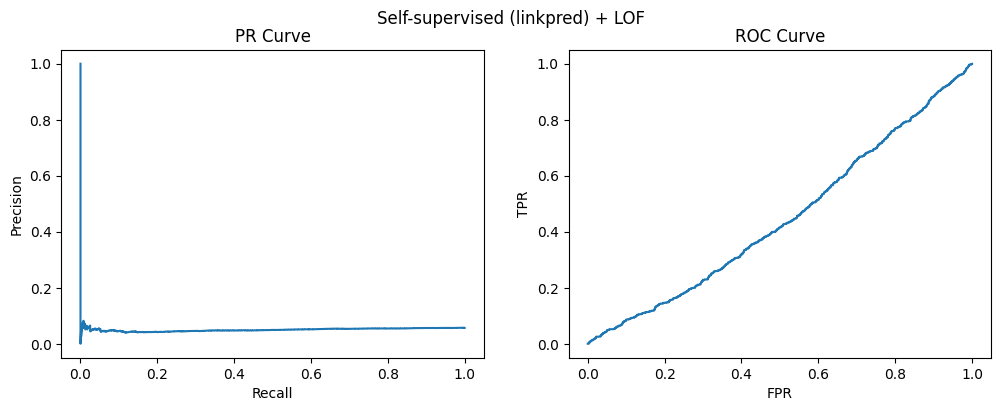

In [37]:
# LOF on embeddings (fit on train only)
lof_z = LocalOutlierFactor(n_neighbors=20, novelty=True)
lof_z.fit(Z_scaled[train_idx])
lof_z_scores = -lof_z.score_samples(Z_scaled)

results_lof_z = evaluate_scores(lof_z_scores, y, val_idx, test_idx)
print("Self-sup Embeddings + LOF Results:", results_lof_z)
plot_curves(lof_z_scores, y, test_idx, title="Self-supervised (linkpred) + LOF")

In [38]:
baseline_results = pd.concat([
    baseline_results,
    pd.DataFrame([
        {"Method": "SelfSup_LinkPred+LOF", **results_lof_z},
    ])
], ignore_index=True)

baseline_results.sort_values("PR_AUC_test", ascending=False)

,Method,ROC_AUC_test,PR_AUC_test,thr_from_val_maxF1,Precision_test,Recall_test,F1_test,Val_bestF1,Val_precision_at_bestF1,Val_recall_at_bestF1
1,LOF,0.668728,0.179724,1.578973,0.076076,0.683962,0.136922,0.263315,0.177517,0.509634
4,Supervised_LogReg,0.826295,0.165486,0.971498,0.159676,0.712264,0.260870,0.548154,0.439095,0.729287
5,SelfSup_LinkPred+LOF,0.448885,0.050302,0.974007,0.056793,0.998428,0.107472,0.206855,0.115359,1.000000
3,AE_oneclass,0.283040,0.037548,0.065941,0.056867,1.000000,0.107614,0.206938,0.115410,1.000000
0,kNN,0.289162,0.037360,0.008741,0.056867,1.000000,0.107614,0.206835,0.115346,1.000000
2,AE,0.270429,0.036986,0.046320,0.056867,1.000000,0.107614,0.206917,0.115397,1.000000


# 7 - **GNN**

Unlike the previously explored methods, which primarily treated nodes as independent observations, **Graph Convolutional Networks (GCNs)** explicitly incorporate graph topology into the learning process. By combining **node features** (`X_scaled`) with **graph connectivity information** (`edge_index`), GCNs perform **message passing**, allowing each node to update its representation by aggregating information from neighboring nodes. This enables the model to capture both individual node characteristics and structural dependencies within the network.

To minimize **temporal information leakage**, graph connectivity is constructed according to the corresponding evaluation stage: training uses only **training-time nodes and edges**, validation incorporates **training and validation edges**, and testing considers **all edges available at test time**. The GCN produces an **anomaly score for each node** by applying the sigmoid function to its output logit, yielding an estimated anomaly probability. Model performance is evaluated using **ROC-AUC, PR-AUC (Average Precision), and F1-score**, with the classification threshold determined exclusively from the validation set to ensure a consistent evaluation procedure.

In [39]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.metrics import average_precision_score, roc_auc_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

N = X_scaled.shape[0]
train_mask = np.zeros(N, dtype=bool); train_mask[train_idx] = True
val_mask   = np.zeros(N, dtype=bool); val_mask[val_idx] = True
test_mask  = np.zeros(N, dtype=bool); test_mask[test_idx] = True

trainval_mask = train_mask | val_mask
full_mask = np.ones(N, dtype=bool)

Device: cpu


In [40]:
# --- build normalized sparse adjacency (A_hat = D^-1/2 (A+I) D^-1/2)
def build_norm_adj(edge_index_np, num_nodes, node_mask_bool):
    src = edge_index_np[0]
    dst = edge_index_np[1]

    # keep edges fully inside the allowed node set
    keep = node_mask_bool[src] & node_mask_bool[dst]
    src = src[keep]
    dst = dst[keep]

    # make undirected (GCN usually assumes this)
    src_u = np.concatenate([src, dst])
    dst_u = np.concatenate([dst, src])

    # add self-loops
    self_nodes = np.arange(num_nodes)
    src_all = np.concatenate([src_u, self_nodes])
    dst_all = np.concatenate([dst_u, self_nodes])

    # compute degrees
    deg = np.bincount(src_all, minlength=num_nodes).astype(np.float32)
    deg_inv_sqrt = 1.0 / np.sqrt(np.maximum(deg, 1.0))
    vals = deg_inv_sqrt[src_all] * deg_inv_sqrt[dst_all]

    # build torch sparse COO
    idx = torch.tensor(np.stack([src_all, dst_all]), dtype=torch.long)
    val = torch.tensor(vals, dtype=torch.float32)
    A = torch.sparse_coo_tensor(idx, val, (num_nodes, num_nodes)).coalesce()
    return A

A_train    = build_norm_adj(edge_index, N, train_mask).to(device)
A_trainval = build_norm_adj(edge_index, N, trainval_mask).to(device)
A_full     = build_norm_adj(edge_index, N, full_mask).to(device)

X_torch = torch.tensor(X_scaled, dtype=torch.float32).to(device)
y_torch = torch.tensor(y, dtype=torch.float32).to(device)

train_idx_t = torch.tensor(train_idx, dtype=torch.long).to(device)
val_idx_t   = torch.tensor(val_idx, dtype=torch.long).to(device)
test_idx_t  = torch.tensor(test_idx, dtype=torch.long).to(device)

In [41]:
# --- minimal 2-layer GCN
class GCN(nn.Module):
    def __init__(self, in_dim, hidden_dim=64, dropout=0.5):
        super().__init__()
        self.w1 = nn.Linear(in_dim, hidden_dim, bias=False)
        self.w2 = nn.Linear(hidden_dim, 1, bias=False)
        self.dropout = dropout

    def forward(self, X, A_norm):
        # H1 = ReLU(A X W1)
        H = torch.sparse.mm(A_norm, X)
        H = self.w1(H)
        H = F.relu(H)
        H = F.dropout(H, p=self.dropout, training=self.training)

        # logits = A H W2
        H = torch.sparse.mm(A_norm, H)
        logits = self.w2(H).squeeze(1)  # [N]
        return logits

model = GCN(in_dim=X_scaled.shape[1], hidden_dim=64, dropout=0.5).to(device)

In [42]:
# class imbalance handling
pos = float(y[train_idx].sum())
neg = float(len(train_idx) - pos)
pos_weight = torch.tensor([neg / max(pos, 1.0)], dtype=torch.float32).to(device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

opt = optim.Adam(model.parameters(), lr=1e-2, weight_decay=5e-4)  # minimal + standard

@torch.no_grad()
def scores_from(model, A_used):
    model.eval()
    logits = model(X_torch, A_used)
    return torch.sigmoid(logits).detach().cpu().numpy()

def val_ap_roc(scores):
    yv = y[val_idx]
    sv = scores[val_idx]
    # guard in case a split is degenerate
    if len(np.unique(yv)) < 2:
        return 0.0, 0.0
    return average_precision_score(yv, sv), roc_auc_score(yv, sv)

In [43]:
# --- train with early stopping on val PR-AUC (AP)
best_state = None
best_ap = -1.0
patience = 15
pat = 0

for epoch in range(1, 201):  # up to 200, early stop makes it minimal
    model.train()
    logits = model(X_torch, A_train)
    loss = loss_fn(logits[train_idx_t], y_torch[train_idx_t])

    opt.zero_grad()
    loss.backward()
    opt.step()

    # validate using train+val adjacency (time-consistent)
    if epoch == 1 or epoch % 10 == 0:
        s_val = scores_from(model, A_trainval)
        ap, roc = val_ap_roc(s_val)
        print(f"Epoch {epoch:03d} | loss {loss.item():.4f} | val PR-AUC {ap:.4f} | val ROC-AUC {roc:.4f}")

        if ap > best_ap:
            best_ap = ap
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            pat = 0
        else:
            pat += 1
            if pat >= patience:
                print("Early stopping.")
                break

Epoch 001 | loss 1.2373 | val PR-AUC 0.2711 | val ROC-AUC 0.7725
Epoch 010 | loss 0.5571 | val PR-AUC 0.5045 | val ROC-AUC 0.8878
Epoch 020 | loss 0.4549 | val PR-AUC 0.5748 | val ROC-AUC 0.8992
Epoch 030 | loss 0.3920 | val PR-AUC 0.5393 | val ROC-AUC 0.8990
Epoch 040 | loss 0.3591 | val PR-AUC 0.5641 | val ROC-AUC 0.9089
Epoch 050 | loss 0.3342 | val PR-AUC 0.5374 | val ROC-AUC 0.9142
Epoch 060 | loss 0.3151 | val PR-AUC 0.5322 | val ROC-AUC 0.9172
Epoch 070 | loss 0.2973 | val PR-AUC 0.5153 | val ROC-AUC 0.9166
Epoch 080 | loss 0.2837 | val PR-AUC 0.5319 | val ROC-AUC 0.9226
Epoch 090 | loss 0.2709 | val PR-AUC 0.5389 | val ROC-AUC 0.9254
Epoch 100 | loss 0.2650 | val PR-AUC 0.5335 | val ROC-AUC 0.9265
Epoch 110 | loss 0.2506 | val PR-AUC 0.5970 | val ROC-AUC 0.9317
Epoch 120 | loss 0.2432 | val PR-AUC 0.6010 | val ROC-AUC 0.9355
Epoch 130 | loss 0.2322 | val PR-AUC 0.6336 | val ROC-AUC 0.9394
Epoch 140 | loss 0.2244 | val PR-AUC 0.6917 | val ROC-AUC 0.9443
Epoch 150 | loss 0.2230 |

In [44]:
if best_state is not None:
    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})

In [45]:
gcn_scores = scores_from(model, A_full)

results_gcn = evaluate_scores(gcn_scores, y, val_idx, test_idx)
print("GCN Results:", results_gcn)

GCN Results: {'ROC_AUC_test': 0.8217256453278573, 'PR_AUC_test': 0.457114451235027, 'thr_from_val_maxF1': 0.8798481822013855, 'Precision_test': 0.5333333333333333, 'Recall_test': 0.46540880503144655, 'F1_test': 0.49706129303106633, 'Val_bestF1': 0.7047970479704797, 'Val_precision_at_bestF1': 0.6761061946902654, 'Val_recall_at_bestF1': 0.7360308285163777}


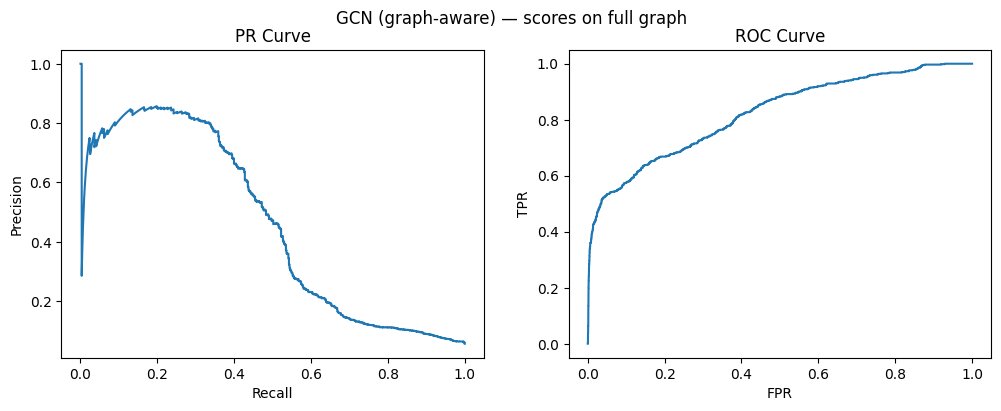

In [46]:
plot_curves(gcn_scores, y, test_idx, title="GCN (graph-aware) — scores on full graph")

In [47]:
baseline_results = pd.concat([
    baseline_results,
    pd.DataFrame([{"Method": "GCN_supervised", **results_gcn}])
], ignore_index=True)
baseline_results.sort_values("PR_AUC_test", ascending=False)

,Method,ROC_AUC_test,PR_AUC_test,thr_from_val_maxF1,Precision_test,Recall_test,F1_test,Val_bestF1,Val_precision_at_bestF1,Val_recall_at_bestF1
6,GCN_supervised,0.821726,0.457114,0.879848,0.533333,0.465409,0.497061,0.704797,0.676106,0.736031
1,LOF,0.668728,0.179724,1.578973,0.076076,0.683962,0.136922,0.263315,0.177517,0.509634
4,Supervised_LogReg,0.826295,0.165486,0.971498,0.159676,0.712264,0.260870,0.548154,0.439095,0.729287
5,SelfSup_LinkPred+LOF,0.448885,0.050302,0.974007,0.056793,0.998428,0.107472,0.206855,0.115359,1.000000
3,AE_oneclass,0.283040,0.037548,0.065941,0.056867,1.000000,0.107614,0.206938,0.115410,1.000000
0,kNN,0.289162,0.037360,0.008741,0.056867,1.000000,0.107614,0.206835,0.115346,1.000000
2,AE,0.270429,0.036986,0.046320,0.056867,1.000000,0.107614,0.206917,0.115397,1.000000
